# SSU Data Dash: quickstart

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/erwinzhang7/SSU-Data-Dash/blob/main/notebooks/quickstart.ipynb)

The same steps as `python run.py validate / report / predict / check`, one cell at a time.
Run the cells from top to bottom. Colab already has every package this needs.

In [10]:
# Setup. In Colab this downloads the starter code; on your own computer it just
# moves to the repo folder.
import os, sys
if "google.colab" in sys.modules:
    if not os.path.exists("/content/SSU-Data-Dash"):
        !git clone -q https://github.com/erwinzhang7/SSU-Data-Dash.git /content/SSU-Data-Dash
    os.chdir("/content/SSU-Data-Dash")
elif os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
sys.path.insert(0, os.getcwd())

# Reload features.py and models.py automatically after you edit them.
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## 1. Get the data

The files download from Hugging Face the first time and are cached for later runs. If you downloaded them by hand, set `DATA_DIR` in the next cell instead.

In [11]:
os.environ["DATA_DIR"] = "datasets"   # only if you downloaded the files yourself

from files import data
import run

listings = data.load("listings")
print(f"{len(listings):,} sales, {listings['date_sold'].min():%B %Y} to {listings['date_sold'].max():%B %Y}")
listings.head()

150,000 sales, January 2021 to May 2026


,ml_num,sold_price,list_price,date_listed,date_sold,days_on_market,house_type_name,house_style,bedrooms,washrooms,...,house_area,lot_front,lot_depth,municipality,community,latitude,longitude,external_avm_estimate,external_avm_estimate_date,remarks
0,SYN-0023247,364100.0,371200.0,2020-12-29,2021-01-01,3,Condo Apt,Apartment,1,1,...,622,NaN,NaN,Toronto,Sumacpark,43.602039,-79.261184,366200.0,2021-02-14,Looking For More Space In A Turnkey Condo? Thi...
1,SYN-0156988,599000.0,595800.0,2020-12-26,2021-01-01,6,Condo Apt,Apartment,2,1,...,649,NaN,NaN,Toronto,Hickorymills,43.695388,-79.510865,622800.0,2021-12-26,"Imagine a quiet evening on Sequoia Trail, wher..."
2,SYN-0087706,492900.0,462200.0,2020-12-22,2021-01-01,10,Condo Apt,Apartment,2,1,...,900-1099,NaN,NaN,North York,Hazelmills,43.740512,-79.386216,NaN,2020-12-03,"Discover this inviting 2-bedroom, 1-bath condo..."
3,SYN-0128154,532300.0,524900.0,2020-12-19,2021-01-01,13,Condo Apt,Apartment,1,1,...,876,NaN,NaN,Scarborough,Sumacbank,43.643774,-79.470180,573600.0,2021-02-22,Sumacbank presents this 1-bedroom condo on Mag...
4,SYN-0118596,564100.0,558300.0,2020-12-05,2021-01-01,27,Condo Apt,Apartment,1,1,...,514,NaN,NaN,Toronto,Ashworth,43.696172,-79.274137,513000.0,2021-02-05,"Morning coffee at the kitchen island, then a s..."


In [12]:
off_market = data.load("off_market")
list_aware = data.load("list_aware")
print(f"{len(off_market):,} homes to value with no list price (off-market)")
print(f"{len(list_aware):,} homes to value that have a list price (list-aware)")
off_market.head()

3,974 homes to value with no list price (off-market)
4,064 homes to value that have a list price (list-aware)


,ml_num,date_listed,house_type_name,house_style,bedrooms,washrooms,parking_total,garage,house_area,lot_front,lot_depth,municipality,community,latitude,longitude,remarks
0,SYN-0011818,2026-05-04,Condo Apt,Apartment,1,1,0,0.0,300-499,NaN,NaN,North York,Hawthornbourne,43.594328,-79.416373,"Located on Elm Crescent, this one-bedroom apar..."
1,SYN-0117584,2026-08-15,Semi-Detached,2-Storey,3,2,2,1.0,1555,21.23,140.10,Scarborough,Spruceview,43.590486,-79.315004,Magnolia Ave in Spruceview – a solid semi with...
2,SYN-0065643,2026-05-05,Condo Apt,Apartment,1,1,1,0.0,685,NaN,NaN,Toronto,Sprucehaven,43.604231,-79.368203,Looking for more space in a condo? This 685 sq...
3,SYN-0031502,2026-09-04,Condo Apt,Apartment,2,1,0,0.0,500-699,NaN,NaN,Toronto,Cypressdale,43.720574,-79.388083,If you're a small family looking for a smart s...
4,SYN-0003276,2026-06-05,Detached,2-Storey,5,5,2,2.0,2844,65.17,129.14,Scarborough,Rowangardens,43.688588,-79.437290,Experience life on Spruce Crescent in Rowangar...


## 2. Validate

Each month from December 2025 to May 2026 is predicted by models trained only on the sales
before it, the same way the real test works. This takes about a minute.

In [14]:
run.validate()

2025-12: trained on 139,931 earlier sales, predicted 1,238 homes
2026-01: trained on 141,169 earlier sales, predicted 1,058 homes
2026-02: trained on 142,227 earlier sales, predicted 1,442 homes
2026-03: trained on 143,669 earlier sales, predicted 1,816 homes
2026-04: trained on 145,485 earlier sales, predicted 2,224 homes
2026-05: trained on 147,709 earlier sales, predicted 2,291 homes
Wrote outputs\validation_predictions.csv


# Validation report

Walk-forward validation, 2025-12 to 2026-05: each month was predicted by models trained only on the sales before it.
Errors are (predicted - sold) / sold. Brackets: bootstrap 95% interval.

| Track | Homes | MAPE | MdAPE | Median signed error |
|---|---|---|---|---|
| off_market | 10,069 | 27.43% (26.95 to 27.94) | 20.84% (20.40 to 21.36) | +8.07% |
| list_aware | 10,069 | 5.78% (5.69 to 5.88) | 4.59% (4.47 to 4.68) | +0.62% |

MAPE: mean absolute percentage error. MdAPE: median absolute percentage error.
A median signed error above 0 means the model tends to predict too high.
The intervals treat homes as independent. Homes sold in the same month share the same
market swings, so the real uncertainty is somewhat wider.

![Error by price range](../figures/error_by_price_range.png)

Wrote reports/validation_report.md, reports/validation_report.json, reports/results_table.tex and figures/error_by_price_range.png


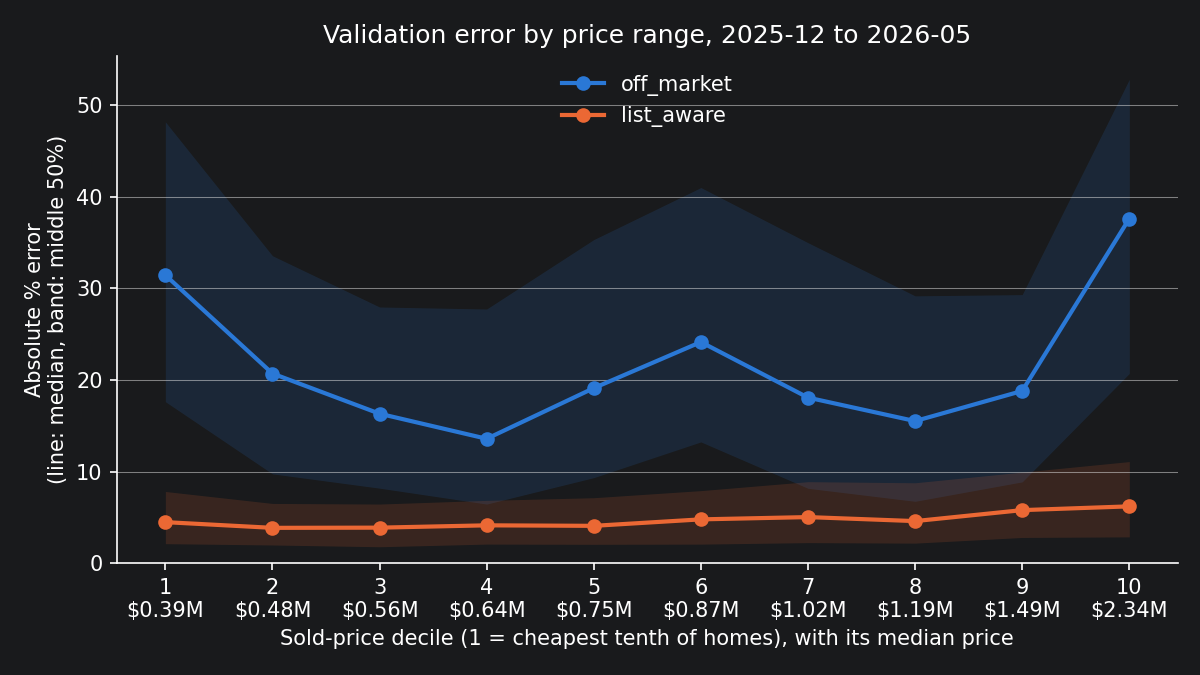

In [15]:
run.report()
from IPython.display import Image
Image("figures/error_by_price_range.png")

## 3. Improve the models

Edit **features.py** and **models.py**, then rerun the two cells above to see whether your
validation error goes down. In Colab, open them from the folder icon on the left
(`SSU-Data-Dash`), edit, and save with Ctrl+S (Cmd+S on a Mac).
Colab deletes your files when the session ends, so download anything you change.

## 4. Predict and check

This fits the models on all 150,000 sales and writes the two submission files.

In [16]:
run.predict()
run.check()

Wrote submissions\submission_off_market.csv (3,974 homes)
Wrote submissions\submission_list_aware.csv (4,064 homes)
submission_off_market.csv: OK
submission_list_aware.csv: OK


True

In [ ]:
# In Colab: download the two submission files.
if "google.colab" in sys.modules:
    from google.colab import files
    files.download("submissions/submission_off_market.csv")
    files.download("submissions/submission_list_aware.csv")